Device dipakai: cpu
Kelas terdeteksi: ['coklat', 'kuning_langsat', 'putih']
Total data: 930
Train: 651 | Val: 139 | Test: 140
  Train: coklat=224, kuning_langsat=214, putih=213
  Val: coklat=51, kuning_langsat=48, putih=40
  Test: coklat=46, kuning_langsat=45, putih=49
Class weights: [0.969, 1.014, 1.019]

Epoch 1/15
train Loss: 1.0671 Acc: 0.4409
val Loss: 0.9257 Acc: 0.6619

Epoch 2/15
train Loss: 0.9362 Acc: 0.5653
val Loss: 0.8301 Acc: 0.6331

Epoch 3/15
train Loss: 0.8517 Acc: 0.6421
val Loss: 0.7604 Acc: 0.6619

Epoch 4/15
train Loss: 0.8227 Acc: 0.6743
val Loss: 0.7084 Acc: 0.7338

Epoch 5/15
train Loss: 0.7752 Acc: 0.6943
val Loss: 0.6884 Acc: 0.7194

Epoch 6/15
train Loss: 0.7484 Acc: 0.7189
val Loss: 0.6678 Acc: 0.7338

Epoch 7/15
train Loss: 0.7239 Acc: 0.7174
val Loss: 0.6301 Acc: 0.7842

Epoch 8/15
train Loss: 0.6875 Acc: 0.7496
val Loss: 0.6316 Acc: 0.7842

Epoch 9/15
train Loss: 0.7006 Acc: 0.7235
val Loss: 0.5883 Acc: 0.7626

Epoch 10/15
train Loss: 0.6802 Acc: 0.7358
v

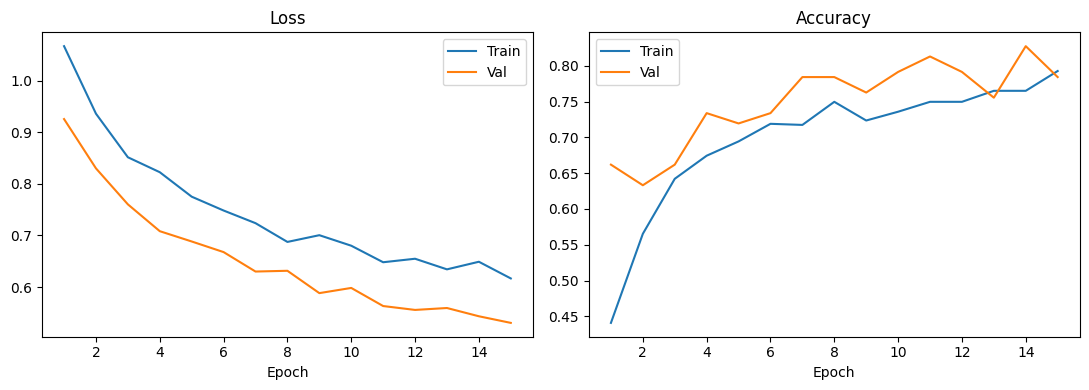

Kurva training tersimpan di: C:\Users\Alvin\Documents\data_ta\training_curves_resnet18.png

Test Acc: 0.8500

Classification Report:
                precision    recall  f1-score   support

        coklat     0.7885    0.8913    0.8367        46
kuning_langsat     0.8947    0.7556    0.8193        45
         putih     0.8800    0.8980    0.8889        49

      accuracy                         0.8500       140
     macro avg     0.8544    0.8483    0.8483       140
  weighted avg     0.8547    0.8500    0.8494       140

Confusion Matrix:
 [[41  2  3]
 [ 8 34  3]
 [ 3  2 44]]


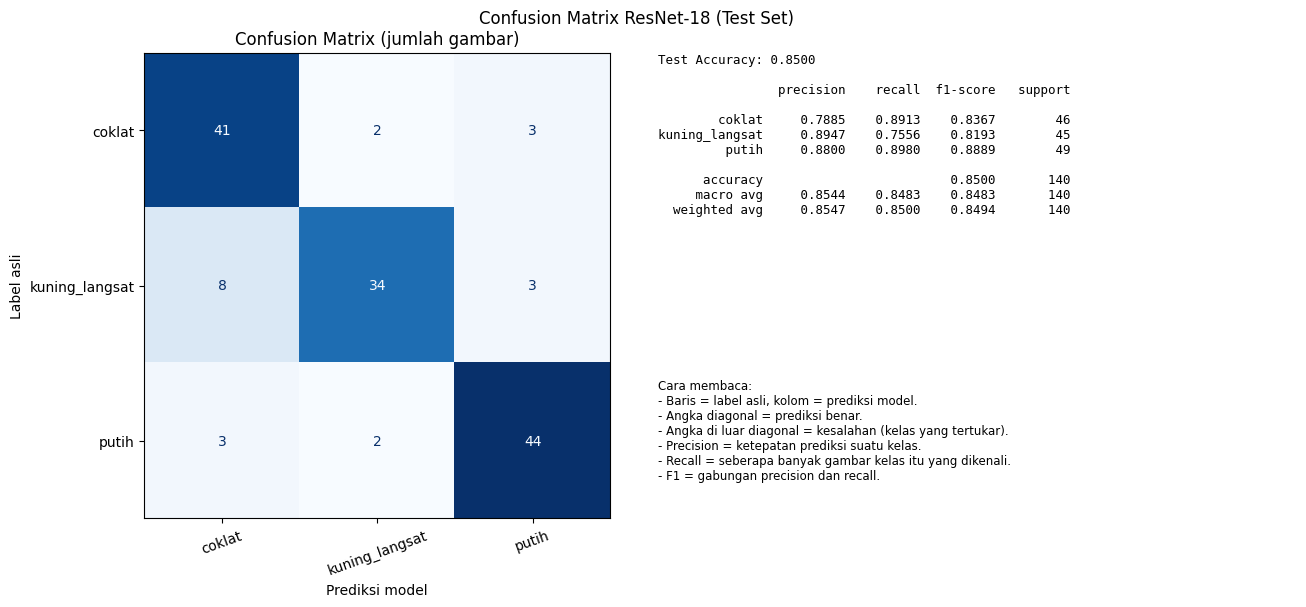

Confusion matrix tersimpan di: C:\Users\Alvin\Documents\data_ta\confusion_matrix_resnet18.png


In [1]:
import copy
import os
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# ==== Tampilan hasil di jendela ====
SHOW_PLOTS = True   # False = hanya simpan gambar ke file, tanpa membuka jendela
_PLOT_STATE = {"show": SHOW_PLOTS}


def finish_figure():
    """Tampilkan figure saat ini di jendela (tanpa memblokir script), atau tutup jika SHOW_PLOTS=False."""
    if _PLOT_STATE["show"]:
        plt.show(block=False)
        plt.pause(0.2)
    else:
        plt.close()


def finalize_plots():
    """Menahan semua jendela tetap terbuka sampai Anda menutupnya."""
    if _PLOT_STATE["show"] and plt.get_fignums():
        print("\nSemua jendela grafik terbuka. Tutup semua jendela untuk mengakhiri script.")
        plt.show()


# ==== 1. Konfigurasi ====
SEED = 42
num_classes = 3
num_epochs = 15
batch_size = 32
lr = 0.001

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15          # sisanya (15%) menjadi test
USE_CLASS_WEIGHTS = True  # atasi data imbalance
FREEZE_BN = True          # jaga BatchNorm backbone tetap eval

data_dir = r"C:\Users\Alvin\Documents\data_ta\hasil_label"
output_dir = r"C:\Users\Alvin\Documents\data_ta"
save_path = os.path.join(output_dir, "resnet18_skintone.pth")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def plot_result_figure(cm, class_names, report_text, title, path):
    """Confusion matrix (kiri) + angka evaluasi (kanan) dalam satu jendela."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 6.0), gridspec_kw={"width_ratios": [1, 1.2]})
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax1, cmap="Blues", values_format="d", colorbar=False)
    ax1.set_title("Confusion Matrix (jumlah gambar)")
    ax1.set_xlabel("Prediksi model")
    ax1.set_ylabel("Label asli")
    ax1.tick_params(axis="x", rotation=20)
    ax2.axis("off")
    ax2.text(0.0, 1.0, report_text, family="monospace", fontsize=9, va="top")
    ax2.text(0.0, 0.30,
             "Cara membaca:\n"
             "- Baris = label asli, kolom = prediksi model.\n"
             "- Angka diagonal = prediksi benar.\n"
             "- Angka di luar diagonal = kesalahan (kelas yang tertukar).\n"
             "- Precision = ketepatan prediksi suatu kelas.\n"
             "- Recall = seberapa banyak gambar kelas itu yang dikenali.\n"
             "- F1 = gabungan precision dan recall.",
             fontsize=8.5, va="top")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    finish_figure()


def main():
    set_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device dipakai:", device)

    # ==== 2. Transformasi gambar ====
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    eval_transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    # ==== 3. Load dataset & split train / val / test ====
    # Dua objek ImageFolder: satu dengan augmentasi (train), satu tanpa (val/test).
    # Urutan file sama, jadi indeks hasil split bisa dipakai bersama.
    train_full = datasets.ImageFolder(data_dir, transform=train_transform)
    eval_full = datasets.ImageFolder(data_dir, transform=eval_transform)

    class_names = train_full.classes
    total = len(train_full)
    print("Kelas terdeteksi:", class_names)
    print("Total data:", total)

    train_size = int(TRAIN_RATIO * total)
    val_size = int(VAL_RATIO * total)
    test_size = total - train_size - val_size

    split_gen = torch.Generator().manual_seed(SEED)
    train_idx, val_idx, test_idx = [
        s.indices for s in random_split(range(total), [train_size, val_size, test_size], generator=split_gen)
    ]

    train_dataset = Subset(train_full, train_idx)
    val_dataset = Subset(eval_full, val_idx)
    test_dataset = Subset(eval_full, test_idx)

    print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

    # Distribusi kelas per split
    targets = np.array(train_full.targets)
    for name, idx in [("Train", train_idx), ("Val", val_idx), ("Test", test_idx)]:
        counts = np.bincount(targets[idx], minlength=num_classes)
        print(f"  {name}: " + ", ".join(f"{c}={n}" for c, n in zip(class_names, counts)))

    dataloaders = {
        "train": DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0),
        "val": DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0),
        "test": DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0),
    }
    dataset_sizes = {k: len(v.dataset) for k, v in dataloaders.items()}

    # ==== 4. ResNet-18 pretrained, ganti layer terakhir ====
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    for param in model.parameters():
        param.requires_grad = False

    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    model = model.to(device)

    # ==== 5. Loss & optimizer ====
    if USE_CLASS_WEIGHTS:
        train_counts = np.bincount(targets[train_idx], minlength=num_classes)
        weights = len(train_idx) / (num_classes * np.maximum(train_counts, 1))
        class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
        print("Class weights:", [round(float(w), 3) for w in weights])
        criterion = nn.CrossEntropyLoss(weight=class_weights)
    else:
        criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(model.fc.parameters(), lr=lr)

    # ==== 6. Training loop ====
    def train_model(model, criterion, optimizer, num_epochs):
        best_wts = copy.deepcopy(model.state_dict())
        best_acc = 0.0
        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

        for epoch in range(num_epochs):
            print(f"\nEpoch {epoch + 1}/{num_epochs}")

            for phase in ["train", "val"]:
                if phase == "train":
                    model.train()
                    if FREEZE_BN:
                        # semua bagian backbone ke eval agar BN running stats tidak berubah
                        for name, module in model.named_children():
                            if name != "fc":
                                module.eval()
                else:
                    model.eval()

                running_loss, running_corrects = 0.0, 0

                for inputs, labels in dataloaders[phase]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()

                    with torch.set_grad_enabled(phase == "train"):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        if phase == "train":
                            loss.backward()
                            optimizer.step()

                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data).item()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects / dataset_sizes[phase]
                history[f"{phase}_loss"].append(epoch_loss)
                history[f"{phase}_acc"].append(epoch_acc)
                print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

                if phase == "val" and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_wts = copy.deepcopy(model.state_dict())

        print(f"\nBest val Acc: {best_acc:.4f}")
        model.load_state_dict(best_wts)
        return model, history

    model, history = train_model(model, criterion, optimizer, num_epochs)

    # Simpan model terbaik (state_dict + nama kelas)
    torch.save({"state_dict": model.state_dict(), "class_names": class_names}, save_path)
    print(f"Model tersimpan di: {save_path}")

    # ==== 7. Kurva training ====
    epochs = range(1, num_epochs + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Val")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Val")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.tight_layout()
    curve_path = os.path.join(output_dir, "training_curves_resnet18.png")
    plt.savefig(curve_path, dpi=150)
    finish_figure()
    print(f"Kurva training tersimpan di: {curve_path}")

    # ==== 8. Evaluasi akhir di TEST set (sekali saja) ====
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in dataloaders["test"]:
            inputs = inputs.to(device)
            preds = model(inputs).argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    test_acc = float(np.mean(np.array(all_preds) == np.array(all_labels)))
    print(f"\nTest Acc: {test_acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

    cm = confusion_matrix(all_labels, all_preds, labels=range(num_classes))
    print("Confusion Matrix:\n", cm)

    cm_path = os.path.join(output_dir, "confusion_matrix_resnet18.png")
    report_text = f"Test Accuracy: {test_acc:.4f}\n\n" + classification_report(
        all_labels, all_preds, labels=list(range(num_classes)), target_names=class_names,
        digits=4, zero_division=0)
    plot_result_figure(cm, class_names, report_text, "Confusion Matrix ResNet-18 (Test Set)", cm_path)
    print(f"Confusion matrix tersimpan di: {cm_path}")


if __name__ == "__main__":
    main()
    finalize_plots()

Device dipakai: cpu
Kelas terdeteksi: ['coklat', 'kuning_langsat', 'putih']
Train: 651 | Val: 139 | Test: 140
Checkpoint tahap 1 dimuat dari: C:\Users\Alvin\Documents\data_ta\resnet18_skintone.pth
Test Acc tahap 1 (baseline): 0.8500
Layer dilatih: ['fc', 'layer4'] | Parameter dilatih: 8,395,267 / 11,178,051

Epoch 1/15
train Loss: 0.7571 Acc: 0.6836
val Loss: 0.3533 Acc: 0.9065

Epoch 2/15
train Loss: 0.3678 Acc: 0.8710
val Loss: 0.2732 Acc: 0.8993

Epoch 3/15
train Loss: 0.3999 Acc: 0.8510
val Loss: 0.3005 Acc: 0.8705

Epoch 4/15
train Loss: 0.3203 Acc: 0.8817
val Loss: 0.1823 Acc: 0.9353

Epoch 5/15
train Loss: 0.3156 Acc: 0.8740
val Loss: 0.1577 Acc: 0.9353

Epoch 6/15
train Loss: 0.3090 Acc: 0.8817
val Loss: 0.1933 Acc: 0.9137

Epoch 7/15
train Loss: 0.2898 Acc: 0.8710
val Loss: 0.1081 Acc: 0.9640

Epoch 8/15
train Loss: 0.2652 Acc: 0.9048
val Loss: 0.1740 Acc: 0.9137

Epoch 9/15
train Loss: 0.2253 Acc: 0.9124
val Loss: 0.1116 Acc: 0.9496

Epoch 10/15
train Loss: 0.2183 Acc: 0.9109

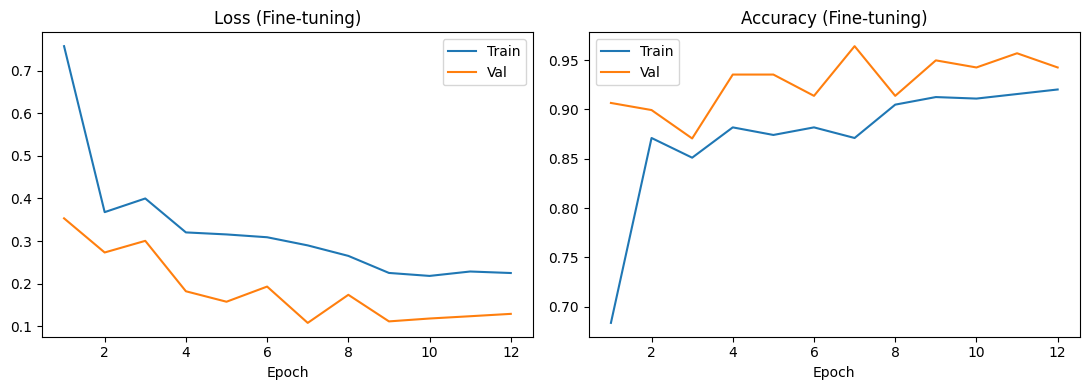

Kurva training tersimpan di: C:\Users\Alvin\Documents\data_ta\training_curves_resnet18_finetuned.png

Test Acc tahap 1 (baseline) : 0.8500
Test Acc tahap 2 (fine-tune): 0.9571

Classification Report (fine-tuned):
                precision    recall  f1-score   support

        coklat     0.9167    0.9565    0.9362        46
kuning_langsat     0.9535    0.9111    0.9318        45
         putih     1.0000    1.0000    1.0000        49

      accuracy                         0.9571       140
     macro avg     0.9567    0.9559    0.9560       140
  weighted avg     0.9577    0.9571    0.9571       140

Confusion Matrix:
 [[44  2  0]
 [ 4 41  0]
 [ 0  0 49]]


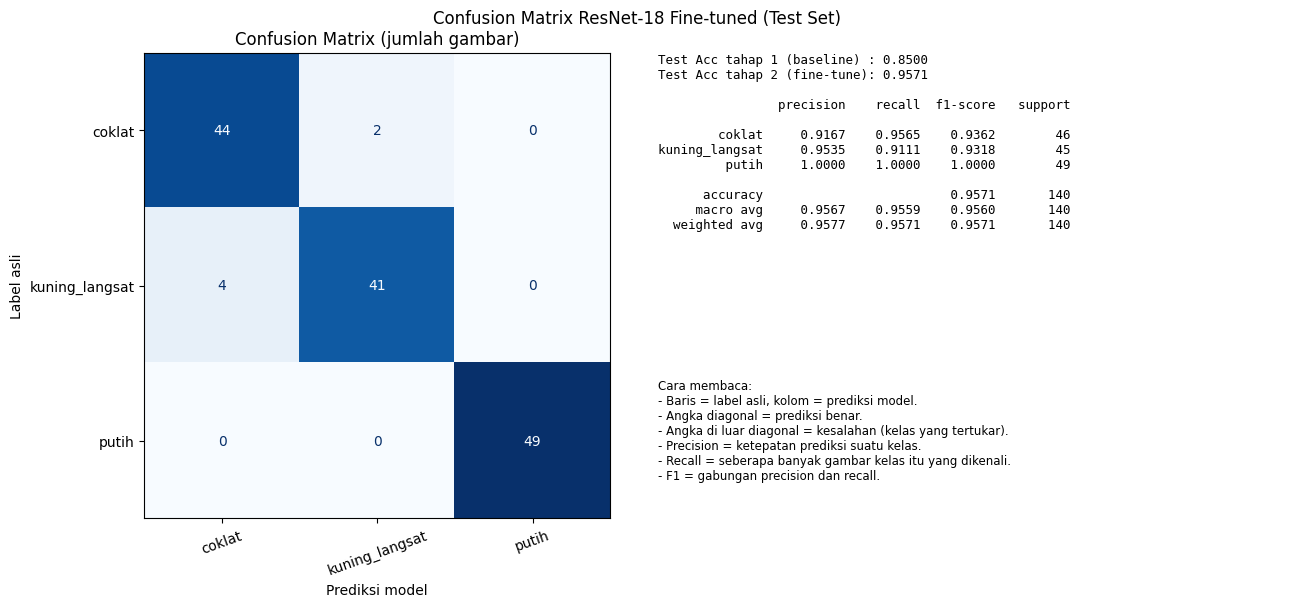

Confusion matrix tersimpan di: C:\Users\Alvin\Documents\data_ta\confusion_matrix_resnet18_finetuned.png


In [2]:
"""
Tahap 2 ResNet-18: Fine-tuning.

Tahap 1 (step1_train_resnet18.py) hanya melatih layer fc.
Di tahap 2, checkpoint tahap 1 dimuat, lalu layer4 ikut dilatih (unfreeze)
dengan learning rate kecil. Split data memakai SEED yang sama dengan tahap 1,
sehingga test set identik dan hasil kedua tahap bisa dibandingkan langsung.
"""
import copy
import os
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# ==== Tampilan hasil di jendela ====
SHOW_PLOTS = True   # False = hanya simpan gambar ke file, tanpa membuka jendela
_PLOT_STATE = {"show": SHOW_PLOTS}


def finish_figure():
    """Tampilkan figure saat ini di jendela (tanpa memblokir script), atau tutup jika SHOW_PLOTS=False."""
    if _PLOT_STATE["show"]:
        plt.show(block=False)
        plt.pause(0.2)
    else:
        plt.close()


def finalize_plots():
    """Menahan semua jendela tetap terbuka sampai Anda menutupnya."""
    if _PLOT_STATE["show"] and plt.get_fignums():
        print("\nSemua jendela grafik terbuka. Tutup semua jendela untuk mengakhiri script.")
        plt.show()


# ==== 1. Konfigurasi ====
SEED = 42                 # HARUS sama dengan tahap 1
num_classes = 3
num_epochs = 15
batch_size = 32

TRAIN_RATIO = 0.70        # HARUS sama dengan tahap 1
VAL_RATIO = 0.15          # HARUS sama dengan tahap 1
USE_CLASS_WEIGHTS = True

UNFREEZE_LAYERS = ["layer4"]   # bisa ["layer3", "layer4"] jika data cukup banyak
LR_BACKBONE = 1e-4             # lr untuk layer yang di-unfreeze
LR_HEAD = 1e-4                 # lr untuk fc (sudah terlatih di tahap 1)
WEIGHT_DECAY = 1e-4
PATIENCE = 5                   # early stopping (epoch tanpa perbaikan val acc)

data_dir = r"C:\Users\Alvin\Documents\data_ta\hasil_label"
output_dir = r"C:\Users\Alvin\Documents\data_ta"
stage1_path = os.path.join(output_dir, "resnet18_skintone.pth")
save_path = os.path.join(output_dir, "resnet18_skintone_finetuned.pth")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def evaluate(model, loader, device):
    model.eval()
    preds_all, labels_all = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            preds = model(inputs.to(device)).argmax(1).cpu().numpy()
            preds_all.extend(preds)
            labels_all.extend(labels.numpy())
    preds_all, labels_all = np.array(preds_all), np.array(labels_all)
    return float(np.mean(preds_all == labels_all)), labels_all, preds_all


def plot_result_figure(cm, class_names, report_text, title, path):
    """Confusion matrix (kiri) + angka evaluasi (kanan) dalam satu jendela."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 6.0), gridspec_kw={"width_ratios": [1, 1.2]})
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax1, cmap="Blues", values_format="d", colorbar=False)
    ax1.set_title("Confusion Matrix (jumlah gambar)")
    ax1.set_xlabel("Prediksi model")
    ax1.set_ylabel("Label asli")
    ax1.tick_params(axis="x", rotation=20)
    ax2.axis("off")
    ax2.text(0.0, 1.0, report_text, family="monospace", fontsize=9, va="top")
    ax2.text(0.0, 0.30,
             "Cara membaca:\n"
             "- Baris = label asli, kolom = prediksi model.\n"
             "- Angka diagonal = prediksi benar.\n"
             "- Angka di luar diagonal = kesalahan (kelas yang tertukar).\n"
             "- Precision = ketepatan prediksi suatu kelas.\n"
             "- Recall = seberapa banyak gambar kelas itu yang dikenali.\n"
             "- F1 = gabungan precision dan recall.",
             fontsize=8.5, va="top")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    finish_figure()


def main():
    set_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device dipakai:", device)

    # ==== 2. Transformasi ====
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    eval_transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    # ==== 3. Dataset & split (identik dengan tahap 1) ====
    train_full = datasets.ImageFolder(data_dir, transform=train_transform)
    eval_full = datasets.ImageFolder(data_dir, transform=eval_transform)
    class_names = train_full.classes
    total = len(train_full)
    print("Kelas terdeteksi:", class_names)

    train_size = int(TRAIN_RATIO * total)
    val_size = int(VAL_RATIO * total)
    test_size = total - train_size - val_size

    split_gen = torch.Generator().manual_seed(SEED)
    train_idx, val_idx, test_idx = [
        s.indices for s in random_split(range(total), [train_size, val_size, test_size], generator=split_gen)
    ]

    train_dataset = Subset(train_full, train_idx)
    val_dataset = Subset(eval_full, val_idx)
    test_dataset = Subset(eval_full, test_idx)
    print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

    targets = np.array(train_full.targets)
    dataloaders = {
        "train": DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0),
        "val": DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0),
        "test": DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0),
    }
    dataset_sizes = {k: len(v.dataset) for k, v in dataloaders.items()}

    # ==== 4. Muat model tahap 1 ====
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)

    checkpoint = torch.load(stage1_path, map_location="cpu")
    state = checkpoint["state_dict"] if isinstance(checkpoint, dict) and "state_dict" in checkpoint else checkpoint
    model.load_state_dict(state)
    model = model.to(device)
    print(f"Checkpoint tahap 1 dimuat dari: {stage1_path}")

    # Baseline: performa tahap 1 di test set (sebagai pembanding)
    base_acc, _, _ = evaluate(model, dataloaders["test"], device)
    print(f"Test Acc tahap 1 (baseline): {base_acc:.4f}")

    # ==== 5. Unfreeze layer terpilih ====
    trainable_names = set(UNFREEZE_LAYERS) | {"fc"}

    for name, module in model.named_children():
        requires = name in trainable_names
        for p in module.parameters():
            p.requires_grad = requires

    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"Layer dilatih: {sorted(trainable_names)} | Parameter dilatih: {n_train:,} / {n_total:,}")

    # ==== 6. Loss & optimizer (learning rate berbeda per grup) ====
    if USE_CLASS_WEIGHTS:
        train_counts = np.bincount(targets[train_idx], minlength=num_classes)
        weights = len(train_idx) / (num_classes * np.maximum(train_counts, 1))
        criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32).to(device))
    else:
        criterion = nn.CrossEntropyLoss()

    backbone_params = [p for n, m in model.named_children() if n in UNFREEZE_LAYERS for p in m.parameters()]
    optimizer = optim.Adam([
        {"params": backbone_params, "lr": LR_BACKBONE},
        {"params": model.fc.parameters(), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    def set_train_mode(model):
        model.train()
        # bagian yang tetap beku -> eval agar BN running stats tidak berubah
        for name, module in model.named_children():
            if name not in trainable_names:
                module.eval()

    # ==== 7. Training loop dengan early stopping ====
    best_wts = copy.deepcopy(model.state_dict())
    best_acc, no_improve = 0.0, 0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch + 1}/{num_epochs}")

        for phase in ["train", "val"]:
            if phase == "train":
                set_train_mode(model)
            else:
                model.eval()

            running_loss, running_corrects = 0.0, 0

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data).item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]
            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)
            print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == "val":
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_wts = copy.deepcopy(model.state_dict())
                    no_improve = 0
                else:
                    no_improve += 1

        scheduler.step()

        if no_improve >= PATIENCE:
            print(f"\nEarly stopping: tidak ada perbaikan val acc selama {PATIENCE} epoch.")
            break

    print(f"\nBest val Acc: {best_acc:.4f}")
    model.load_state_dict(best_wts)

    torch.save({"state_dict": model.state_dict(), "class_names": class_names}, save_path)
    print(f"Model fine-tuned tersimpan di: {save_path}")

    # ==== 8. Kurva training ====
    ran = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(ran, history["train_loss"], label="Train")
    axes[0].plot(ran, history["val_loss"], label="Val")
    axes[0].set_title("Loss (Fine-tuning)"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(ran, history["train_acc"], label="Train")
    axes[1].plot(ran, history["val_acc"], label="Val")
    axes[1].set_title("Accuracy (Fine-tuning)"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.tight_layout()
    curve_path = os.path.join(output_dir, "training_curves_resnet18_finetuned.png")
    plt.savefig(curve_path, dpi=150)
    finish_figure()
    print(f"Kurva training tersimpan di: {curve_path}")

    # ==== 9. Evaluasi akhir di TEST set ====
    test_acc, y_true, y_pred = evaluate(model, dataloaders["test"], device)
    print(f"\nTest Acc tahap 1 (baseline) : {base_acc:.4f}")
    print(f"Test Acc tahap 2 (fine-tune): {test_acc:.4f}")

    print("\nClassification Report (fine-tuned):")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
    print("Confusion Matrix:\n", cm)

    cm_path = os.path.join(output_dir, "confusion_matrix_resnet18_finetuned.png")
    report_text = f"Test Acc tahap 1 (baseline) : {base_acc:.4f}\nTest Acc tahap 2 (fine-tune): {test_acc:.4f}\n\n" + classification_report(
        y_true, y_pred, labels=list(range(num_classes)), target_names=class_names,
        digits=4, zero_division=0)
    plot_result_figure(cm, class_names, report_text, "Confusion Matrix ResNet-18 Fine-tuned (Test Set)", cm_path)
    print(f"Confusion matrix tersimpan di: {cm_path}")


if __name__ == "__main__":
    main()
    finalize_plots()

Device evaluasi: cpu
Kelas: ['coklat', 'kuning_langsat', 'putih'] | Jumlah data test: 140

[ok] ResNet-18 tahap 1: acc=0.8500, f1_macro=0.8483
[ok] ResNet-18 fine-tuned: acc=0.9571, f1_macro=0.9560

Model                          Acc    Prec  Recall      F1  Param(M)  Ukuran(MB)   CPU(ms)
----------------------------------------------------------------------------------------------------
ResNet-18 tahap 1           0.8500  0.8544  0.8483  0.8483     11.18       42.72      43.1
ResNet-18 fine-tuned        0.9571  0.9567  0.9559  0.9560     11.18       42.72      50.4
Precision/Recall/F1 = macro average. CPU(ms) = waktu inferensi 1 gambar di CPU.


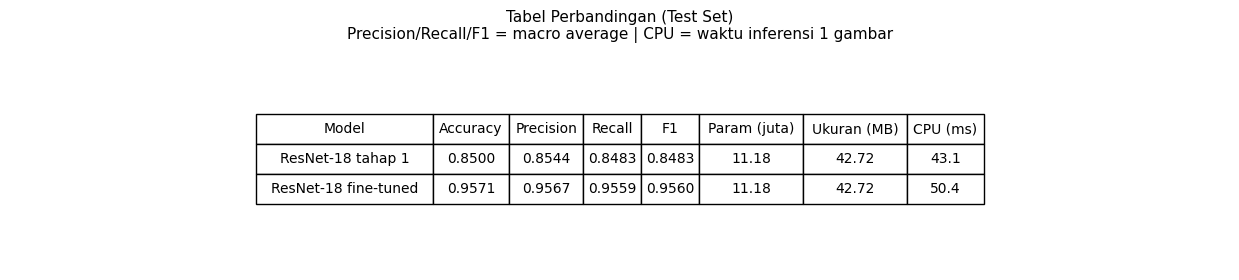

Akurasi test setelah fine-tuning naik: +0.1071

Tabel tersimpan di: C:\Users\Alvin\Documents\data_ta\perbandingan_resnet18.csv


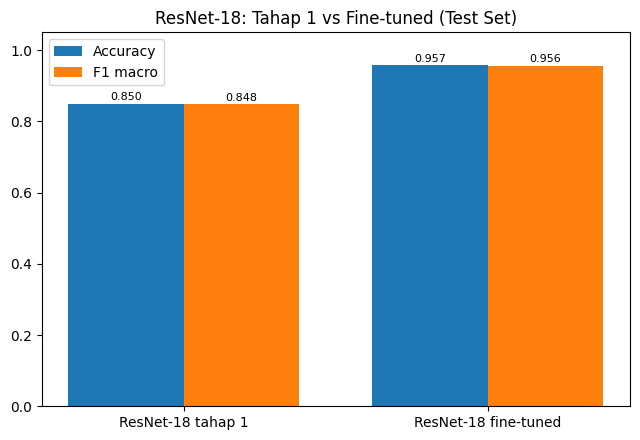

Grafik tersimpan di: C:\Users\Alvin\Documents\data_ta\perbandingan_resnet18.png


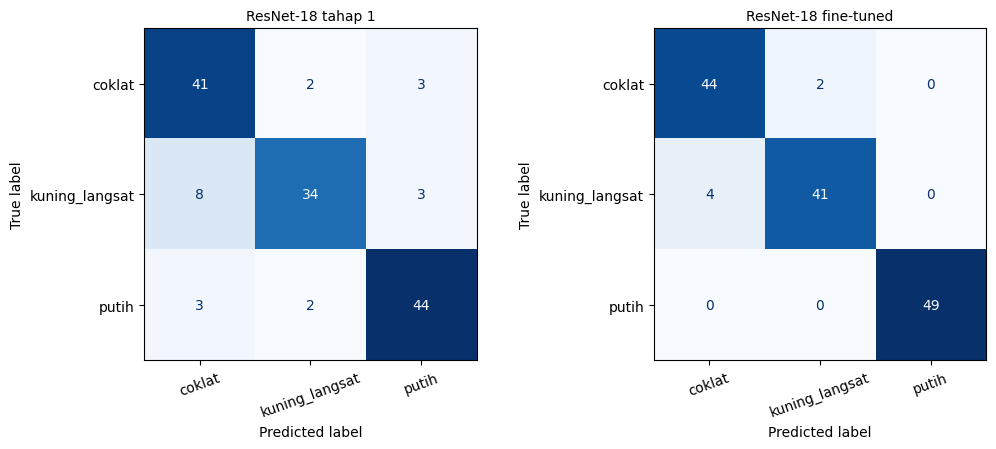

Confusion matrix tersimpan di: C:\Users\Alvin\Documents\data_ta\perbandingan_cm_resnet18.png


In [4]:
"""
ResNet-18 - Tahap 3: Perbandingan tahap 1 (feature extraction) vs tahap 2 (fine-tuned).

Kedua model dievaluasi di TEST set yang sama. Checkpoint yang belum ada dilewati.
Output: tabel di konsol, CSV, grafik batang, dan confusion matrix berdampingan.
"""
import copy
import csv
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, models, transforms

# ==== Tampilan hasil di jendela ====
SHOW_PLOTS = True   # False = hanya simpan gambar ke file, tanpa membuka jendela
_PLOT_STATE = {"show": SHOW_PLOTS}


def finish_figure():
    """Tampilkan figure saat ini di jendela (tanpa memblokir script), atau tutup jika SHOW_PLOTS=False."""
    if _PLOT_STATE["show"]:
        plt.show(block=False)
        plt.pause(0.2)
    else:
        plt.close()


def finalize_plots():
    """Menahan semua jendela tetap terbuka sampai Anda menutupnya."""
    if _PLOT_STATE["show"] and plt.get_fignums():
        print("\nSemua jendela grafik terbuka. Tutup semua jendela untuk mengakhiri script.")
        plt.show()


# ==== Konfigurasi (HARUS sama dengan step1 & step2) ====
SEED = 42
num_classes = 3
batch_size = 32
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

data_dir = r"C:\Users\Alvin\Documents\data_ta\hasil_label"
output_dir = r"C:\Users\Alvin\Documents\data_ta"

CHECKPOINTS = [
    ("ResNet-18 tahap 1", "resnet18_skintone.pth"),
    ("ResNet-18 fine-tuned", "resnet18_skintone_finetuned.pth"),
]

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def load_resnet(path, device):
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    ckpt = torch.load(path, map_location="cpu")
    state = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
    model.load_state_dict(state)
    return model.to(device).eval()


def evaluate(model, loader, device):
    ys, ps = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            ps.extend(model(inputs.to(device)).argmax(1).cpu().numpy())
            ys.extend(labels.numpy())
    return np.array(ys), np.array(ps)


def measure_latency_cpu(model, runs=50, warmup=10):
    """Rata-rata waktu inferensi satu gambar (ms) di CPU, batch size 1."""
    cpu_model = copy.deepcopy(model).cpu().eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        for _ in range(warmup):
            cpu_model(x)
        start = time.perf_counter()
        for _ in range(runs):
            cpu_model(x)
        return (time.perf_counter() - start) / runs * 1000


def show_table_figure(results, path):
    """Tabel angka perbandingan model dalam satu jendela."""
    cols = ["Model", "Accuracy", "Precision", "Recall", "F1", "Param (juta)", "Ukuran (MB)", "CPU (ms)"]
    cells = [[r["model"], f"{r['accuracy']:.4f}", f"{r['precision_macro']:.4f}", f"{r['recall_macro']:.4f}",
              f"{r['f1_macro']:.4f}", f"{r['params_juta']:.2f}", f"{r['ukuran_mb']:.2f}",
              f"{r['latensi_cpu_ms']:.1f}"] for r in results]
    fig, ax = plt.subplots(figsize=(12.5, 1.9 + 0.5 * len(results)))
    ax.axis("off")
    table = ax.table(cellText=cells, colLabels=cols, loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.auto_set_column_width(list(range(len(cols))))
    table.scale(1, 1.8)
    ax.set_title("Tabel Perbandingan (Test Set)\n"
                 "Precision/Recall/F1 = macro average | CPU = waktu inferensi 1 gambar", fontsize=11)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    finish_figure()


def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device evaluasi:", device)

    eval_transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    eval_full = datasets.ImageFolder(data_dir, transform=eval_transform)
    class_names = eval_full.classes
    total = len(eval_full)

    train_size = int(TRAIN_RATIO * total)
    val_size = int(VAL_RATIO * total)
    test_size = total - train_size - val_size
    split_gen = torch.Generator().manual_seed(SEED)
    _, _, test_split = random_split(range(total), [train_size, val_size, test_size], generator=split_gen)
    test_idx = list(test_split.indices)

    loader = DataLoader(Subset(eval_full, test_idx), batch_size=batch_size, shuffle=False, num_workers=0)
    print(f"Kelas: {class_names} | Jumlah data test: {len(test_idx)}\n")

    results, cms = [], {}

    for label, filename in CHECKPOINTS:
        path = os.path.join(output_dir, filename)
        if not os.path.exists(path):
            print(f"[lewati] {label}: {path} tidak ditemukan")
            continue

        model = load_resnet(path, device)
        y_true, y_pred = evaluate(model, loader, device)

        acc = float(np.mean(y_true == y_pred))
        p, r, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=range(num_classes), average="macro", zero_division=0)
        _, _, f1_cls, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=range(num_classes), average=None, zero_division=0)

        row = {
            "model": label,
            "accuracy": acc,
            "precision_macro": float(p),
            "recall_macro": float(r),
            "f1_macro": float(f1),
            "params_juta": sum(q.numel() for q in model.parameters()) / 1e6,
            "ukuran_mb": os.path.getsize(path) / (1024 * 1024),
            "latensi_cpu_ms": measure_latency_cpu(model),
        }
        for name, v in zip(class_names, f1_cls):
            row[f"f1_{name}"] = float(v)

        results.append(row)
        cms[label] = confusion_matrix(y_true, y_pred, labels=range(num_classes))
        print(f"[ok] {label}: acc={acc:.4f}, f1_macro={f1:.4f}")

    if not results:
        print("\nTidak ada checkpoint ditemukan. Jalankan step1 (dan step2) terlebih dahulu.")
        return

    # ==== Tabel di konsol ====
    line = "=" * 100
    print("\n" + line)
    print(f"{'Model':<26}{'Acc':>8}{'Prec':>8}{'Recall':>8}{'F1':>8}{'Param(M)':>10}{'Ukuran(MB)':>12}{'CPU(ms)':>10}")
    print("-" * 100)
    for r in results:
        print(f"{r['model']:<26}{r['accuracy']:>8.4f}{r['precision_macro']:>8.4f}{r['recall_macro']:>8.4f}"
              f"{r['f1_macro']:>8.4f}{r['params_juta']:>10.2f}{r['ukuran_mb']:>12.2f}{r['latensi_cpu_ms']:>10.1f}")
    print(line)
    print("Precision/Recall/F1 = macro average. CPU(ms) = waktu inferensi 1 gambar di CPU.")
    show_table_figure(results, os.path.join(output_dir, "perbandingan_tabel_resnet18.png"))

    if len(results) == 2:
        d = results[1]["accuracy"] - results[0]["accuracy"]
        verdict = "naik" if d > 0 else ("turun" if d < 0 else "tidak berubah")
        print(f"Akurasi test setelah fine-tuning {verdict}: {d:+.4f}")

    # ==== CSV ====
    csv_path = os.path.join(output_dir, "perbandingan_resnet18.csv")
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(results[0].keys()))
        writer.writeheader()
        writer.writerows(results)
    print(f"\nTabel tersimpan di: {csv_path}")

    # ==== Grafik ====
    names = [r["model"] for r in results]
    x = np.arange(len(names))
    w = 0.38
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.bar(x - w / 2, [r["accuracy"] for r in results], w, label="Accuracy")
    ax.bar(x + w / 2, [r["f1_macro"] for r in results], w, label="F1 macro")
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_ylim(0, 1.05)
    ax.set_title("ResNet-18: Tahap 1 vs Fine-tuned (Test Set)")
    ax.legend()
    for i, r in enumerate(results):
        ax.text(i - w / 2, r["accuracy"] + 0.01, f"{r['accuracy']:.3f}", ha="center", fontsize=8)
        ax.text(i + w / 2, r["f1_macro"] + 0.01, f"{r['f1_macro']:.3f}", ha="center", fontsize=8)
    plt.tight_layout()
    bar_path = os.path.join(output_dir, "perbandingan_resnet18.png")
    plt.savefig(bar_path, dpi=150)
    finish_figure()
    print(f"Grafik tersimpan di: {bar_path}")

    # ==== Confusion matrix berdampingan ====
    n = len(cms)
    fig, axes = plt.subplots(1, n, figsize=(5.2 * n, 4.6), squeeze=False)
    for ax, (label, cm) in zip(axes[0], cms.items()):
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=ax, cmap="Blues", values_format="d", colorbar=False)
        ax.set_title(label, fontsize=10)
        ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    cm_path = os.path.join(output_dir, "perbandingan_cm_resnet18.png")
    plt.savefig(cm_path, dpi=150)
    finish_figure()
    print(f"Confusion matrix tersimpan di: {cm_path}")


if __name__ == "__main__":
    main()
    finalize_plots()

Model      : resnet18
Checkpoint : C:\Users\Alvin\Documents\data_ta\resnet18_skintone_finetuned.pth
Kelas      : ['coklat', 'kuning_langsat', 'putih']


Kategori asli: coklat   (gambar: IMG_2999.JPG, sumber: test set)
  Prediksi    : coklat (99.8%)  -> BENAR
  Probabilitas: [coklat: 99.8% | kuning_langsat: 0.2% | putih: 0.0%]
  Rekomendasi warna baju untuk 'coklat': Amethyst (Ungu Keunguan), Ruby (Merah Delima), Turquoise (Biru Kehijauan Cerah), Kuning Cerah (Canary Yellow), Oranye Terang, Fuchsia / Magenta, Putih Gading (Ivory), Emerald Green

Kategori asli: kuning_langsat   (gambar: IMG_2850.JPG, sumber: test set)
  Prediksi    : kuning_langsat (99.9%)  -> BENAR
  Probabilitas: [coklat: 0.0% | kuning_langsat: 99.9% | putih: 0.1%]
  Rekomendasi warna baju untuk 'kuning_langsat': Merah Terang (Fire Red/Scarlet), Oranye (Coral/Tangerine), Kuning (Mustard/Kuning Cerah), Hijau Zaitun (Olive), Krem / Ivory, Cokelat Muda (Tan/Camel), Turquoise / Teal, Merah Marun Lembut (Rust)

Kategori asl

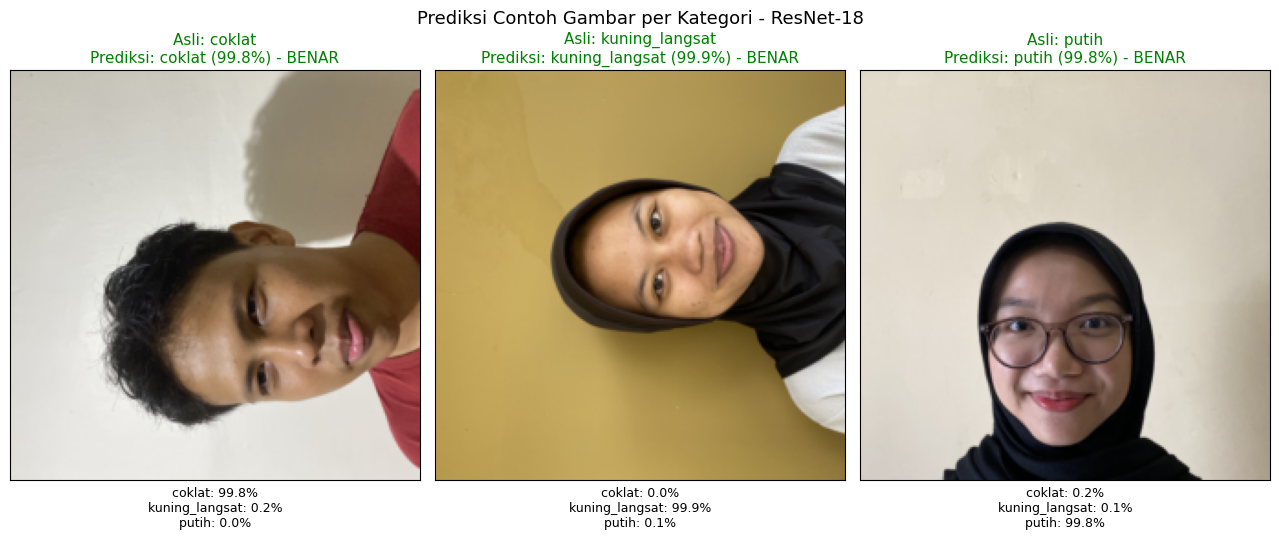

In [11]:
"""
ResNet-18 - Tahap 7: Prediksi contoh gambar dari tiap KATEGORI (coklat, kuning_langsat, putih).

Script mengambil gambar contoh dari tiap kategori di TEST SET (data yang tidak dipakai melatih,
split identik dengan step1/step2), memprediksinya, lalu membandingkan label asli vs prediksi.

Contoh:
  python step7_predict_per_kategori_resnet18.py                  # 1 gambar per kategori
  python step7_predict_per_kategori_resnet18.py --per-class 3    # 3 gambar per kategori
  python step7_predict_per_kategori_resnet18.py --seed 7         # ganti gambar yang terpilih

Hasil: angka di terminal (label asli, prediksi, confidence, BENAR/SALAH, rekomendasi warna baju)
dan satu jendela berisi gambarnya. Gambar juga disimpan sebagai PNG.
"""
import argparse
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import random_split
from torchvision import datasets, models, transforms

# =========================================================
# 1. KONFIGURASI
# =========================================================
MODEL_TYPE = "resnet18"

# HARUS sama dengan step1/step2 agar gambar contoh benar-benar dari test set
SEED = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

data_dir = r"C:\Users\Alvin\Documents\data_ta\hasil_label"
output_dir = r"C:\Users\Alvin\Documents\data_ta"

# Opsional: isi path gambar sendiri untuk kategori tertentu (kosongkan untuk ambil dari test set)
MANUAL_IMAGES = {
    "coklat": r"",
    "kuning_langsat": r"",
    "putih": r"",
}

SHOW_PLOTS = True         # False = hanya simpan PNG, tanpa membuka jendela
DEFAULT_CLASS_NAMES = ["coklat", "kuning_langsat", "putih"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

color_recommendations = {
    "putih": ["Hijau Tua (Emerald/Forest Green)", "Navy / Biru Dongker", "Cokelat Tua (Chocolate)",
              "Emas Tua (Old Gold/Mustard Gelap)", "Burgundy / Merah Marun", "Ungu Tua (Deep Purple/Plum)",
              "Abu-abu Charcoal", "Hitam"],
    "kuning_langsat": ["Merah Terang (Fire Red/Scarlet)", "Oranye (Coral/Tangerine)",
                       "Kuning (Mustard/Kuning Cerah)", "Hijau Zaitun (Olive)", "Krem / Ivory",
                       "Cokelat Muda (Tan/Camel)", "Turquoise / Teal", "Merah Marun Lembut (Rust)"],
    "coklat": ["Amethyst (Ungu Keunguan)", "Ruby (Merah Delima)", "Turquoise (Biru Kehijauan Cerah)",
               "Kuning Cerah (Canary Yellow)", "Oranye Terang", "Fuchsia / Magenta",
               "Putih Gading (Ivory)", "Emerald Green"],
}

resize_crop = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
to_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])


# =========================================================
# 2. MODEL
# =========================================================
def build_model(num_classes):
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def default_checkpoint():
    ft = os.path.join(output_dir, "resnet18_skintone_finetuned.pth")
    s1 = os.path.join(output_dir, "resnet18_skintone.pth")
    return ft if os.path.exists(ft) else s1


def load_model(path, device):
    """Mendukung checkpoint dict {state_dict, class_names} maupun state_dict polos."""
    ckpt = torch.load(path, map_location="cpu")
    if isinstance(ckpt, dict) and "state_dict" in ckpt:
        state, class_names = ckpt["state_dict"], ckpt.get("class_names")
    else:
        state, class_names = ckpt, None
    class_names = list(class_names or DEFAULT_CLASS_NAMES)
    model = build_model(len(class_names))
    model.load_state_dict(state)
    return model.to(device).eval(), class_names


# =========================================================
# 3. PEMILIHAN GAMBAR CONTOH PER KATEGORI
# =========================================================
def get_test_indices(total):
    train_size = int(TRAIN_RATIO * total)
    val_size = int(VAL_RATIO * total)
    test_size = total - train_size - val_size
    gen = torch.Generator().manual_seed(SEED)
    _, _, test_split = random_split(range(total), [train_size, val_size, test_size], generator=gen)
    return list(test_split.indices)


def pick_samples(dataset, test_idx, per_class, rng):
    """Return dict {indeks_kelas: [ {path, source}, ... ]}."""
    targets = np.array(dataset.targets)
    picks = {c: [] for c in range(len(dataset.classes))}

    for c, name in enumerate(dataset.classes):
        remaining = per_class
        manual = MANUAL_IMAGES.get(name, "")
        if manual:
            if not os.path.isfile(manual):
                raise SystemExit(f"Gambar manual untuk '{name}' tidak ditemukan: {manual}")
            picks[c].append({"path": manual, "source": "manual"})
            remaining -= 1

        if remaining > 0:
            candidates = [i for i in test_idx if targets[i] == c]
            if not candidates:
                print(f"[peringatan] Tidak ada gambar test untuk kategori '{name}'.")
                continue
            chosen = rng.choice(candidates, size=min(remaining, len(candidates)), replace=False)
            for i in chosen:
                picks[c].append({"path": dataset.samples[i][0], "source": "test set"})
    return picks


def predict_probs(model, view_img, device):
    x = to_tensor(view_img).unsqueeze(0).to(device)
    with torch.no_grad():
        return torch.softmax(model(x), dim=1)[0].cpu().numpy()


# =========================================================
# 4. MAIN
# =========================================================
def main():
    parser = argparse.ArgumentParser(description="Prediksi contoh gambar tiap kategori (ResNet-18)")
    parser.add_argument("--per-class", type=int, default=1, help="Jumlah gambar contoh per kategori (default 1)")
    parser.add_argument("--seed", type=int, default=SEED, help="Seed pemilihan gambar contoh (ganti untuk gambar lain)")
    parser.add_argument("--checkpoint", default=None, help="Path file .pth (opsional)")
    parser.add_argument("--no-show", action="store_true", help="Jangan buka jendela gambar")
    args, _ = parser.parse_known_args()  # abaikan argumen bawaan Jupyter/Spyder

    show = SHOW_PLOTS and not args.no_show
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    ckpt = args.checkpoint or default_checkpoint()
    if not os.path.exists(ckpt):
        raise SystemExit(f"Checkpoint tidak ditemukan: {ckpt}")
    model, model_classes = load_model(ckpt, device)

    dataset = datasets.ImageFolder(data_dir)  # hanya untuk daftar file & label
    class_names = dataset.classes
    if list(model_classes) != list(class_names):
        print(f"[peringatan] Urutan kelas model {model_classes} berbeda dengan dataset {class_names}.")

    print(f"Model      : {MODEL_TYPE}")
    print(f"Checkpoint : {ckpt}")
    print(f"Kelas      : {class_names}")

    test_idx = get_test_indices(len(dataset))
    rng = np.random.default_rng(args.seed)
    picks = pick_samples(dataset, test_idx, args.per_class, rng)

    # ---- prediksi ----
    results = {c: [] for c in picks}
    for c, samples in picks.items():
        for s in samples:
            img = Image.open(s["path"]).convert("RGB")
            view = resize_crop(img)               # tampilan yang dilihat model (224x224)
            pr = predict_probs(model, view, device)
            idx = int(pr.argmax())
            results[c].append({
                "name": os.path.basename(s["path"]), "source": s["source"], "view": view, "probs": pr,
                "true": class_names[c], "pred": model_classes[idx], "conf": float(pr[idx]),
                "correct": model_classes[idx] == class_names[c],
            })

    # ---- angka di terminal ----
    print("\n" + "=" * 78)
    total, benar = 0, 0
    for c, rows in results.items():
        for r in rows:
            total += 1
            benar += int(r["correct"])
            detail = " | ".join(f"{n}: {v * 100:.1f}%" for n, v in zip(model_classes, r["probs"]))
            print(f"\nKategori asli: {r['true']}   (gambar: {r['name']}, sumber: {r['source']})")
            print(f"  Prediksi    : {r['pred']} ({r['conf'] * 100:.1f}%)  -> {'BENAR' if r['correct'] else 'SALAH'}")
            print(f"  Probabilitas: [{detail}]")
            rec = color_recommendations.get(r["pred"], [])
            if rec:
                print(f"  Rekomendasi warna baju untuk '{r['pred']}': " + ", ".join(rec))
    print("\n" + "=" * 78)
    if total:
        print(f"Ringkasan: {benar} dari {total} gambar contoh diprediksi benar.")
        print("Catatan: ini hanya contoh kecil untuk demo, bukan pengganti evaluasi lengkap di test set "
              "(lihat step1/step2/step3).")

    # ---- gambar: kolom = kategori asli, baris = contoh ke-n ----
    ncols = len(class_names)
    nrows = max((len(v) for v in results.values()), default=0)
    if nrows == 0:
        raise SystemExit("Tidak ada gambar yang bisa diprediksi.")
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 5.2 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for c in range(ncols):
        for r_i, r in enumerate(results.get(c, [])):
            ax = axes[r_i][c]
            ax.axis("on")
            ax.imshow(r["view"])
            ax.set_xticks([])
            ax.set_yticks([])
            status = "BENAR" if r["correct"] else "SALAH"
            ax.set_title(f"Asli: {r['true']}\nPrediksi: {r['pred']} ({r['conf'] * 100:.1f}%) - {status}",
                         fontsize=11, color="green" if r["correct"] else "red")
            ax.set_xlabel("\n".join(f"{n}: {v * 100:.1f}%" for n, v in zip(model_classes, r["probs"])), fontsize=9)
    fig.suptitle("Prediksi Contoh Gambar per Kategori - ResNet-18", fontsize=13)
    plt.tight_layout()

    save_path = os.path.join(output_dir, "prediksi_per_kategori_resnet18.png")
    plt.savefig(save_path, dpi=150)
    print(f"Gambar hasil tersimpan di: {save_path}")

    if show:
        plt.show()
    else:
        plt.close()


if __name__ == "__main__":
    main()

Checkpoint: C:\Users\Alvin\Documents\data_ta\resnet18_skintone_finetuned.pth
Kelas: ['coklat', 'kuning_langsat', 'putih'] | Data test: 140

Test Acc: 0.9571 | Benar: 134 | Salah: 6
Rata-rata confidence (benar): 0.948
Rata-rata confidence (salah): 0.734

Kesalahan paling sering (label asli -> prediksi):
  kuning_langsat -> coklat: 4 gambar
  coklat -> kuning_langsat: 2 gambar


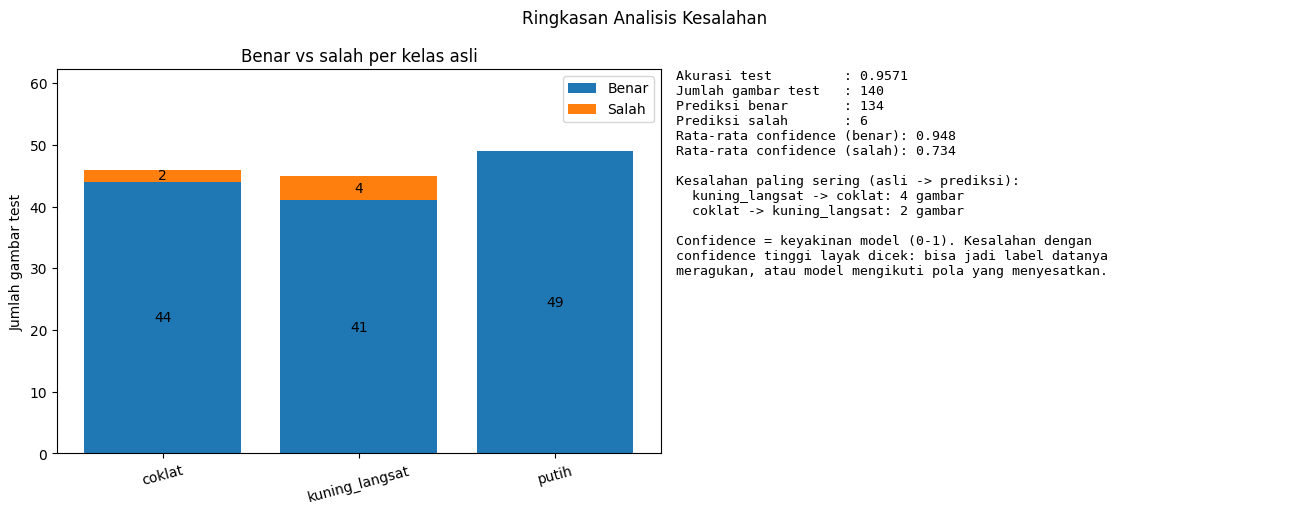


Daftar kesalahan tersimpan di: C:\Users\Alvin\Documents\data_ta\kesalahan_resnet18.csv


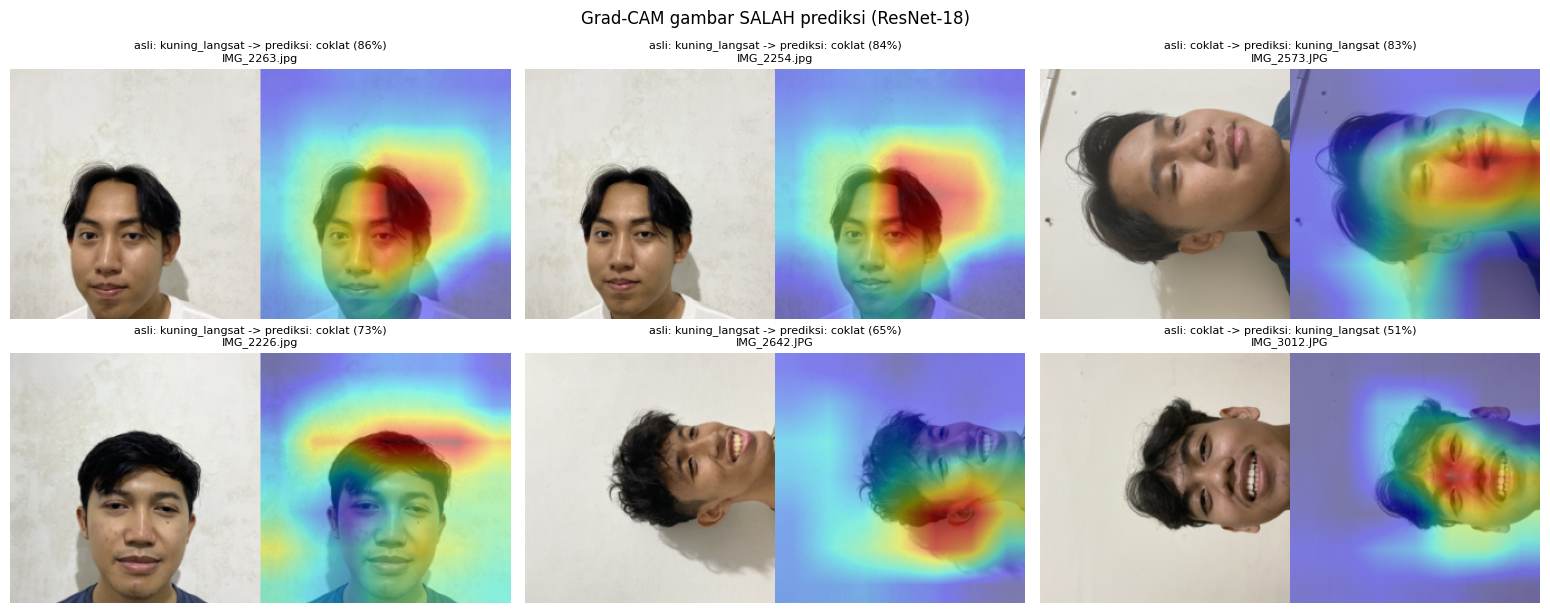

Tersimpan: C:\Users\Alvin\Documents\data_ta\gradcam_salah_resnet18.png


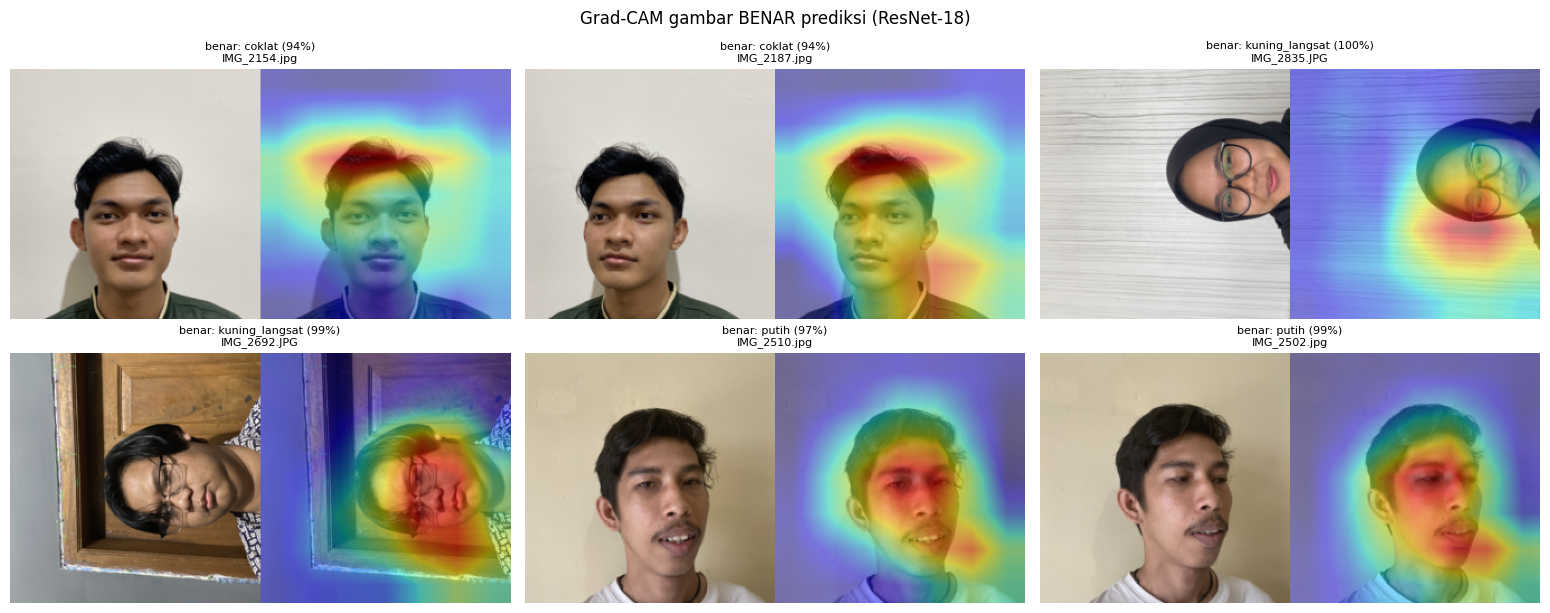

Tersimpan: C:\Users\Alvin\Documents\data_ta\gradcam_benar_resnet18.png

Cara membaca Grad-CAM: area merah/kuning = bagian yang paling mempengaruhi prediksi.
Jika area merah jatuh di latar/rambut/baju dan bukan kulit, model mungkin belajar shortcut.


In [13]:
"""
ResNet-18 - Tahap 5: Analisis kesalahan + Grad-CAM.

- Mencari semua gambar test yang salah prediksi (CSV, confidence tertinggi dulu:
  kesalahan dengan confidence tinggi sering menandakan label meragukan atau pola menyesatkan).
- Menghitung pasangan kelas yang paling sering tertukar.
- Membuat visualisasi Grad-CAM (target layer: model.layer4[-1]).

Contoh:
  python step5_error_analysis_resnet18.py
  python step5_error_analysis_resnet18.py --checkpoint C:\\...\\resnet18_skintone.pth
"""
import argparse
import csv
import math
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, models, transforms

# ==== Tampilan hasil di jendela ====
SHOW_PLOTS = True   # False = hanya simpan gambar ke file, tanpa membuka jendela
_PLOT_STATE = {"show": SHOW_PLOTS}


def finish_figure():
    """Tampilkan figure saat ini di jendela (tanpa memblokir script), atau tutup jika SHOW_PLOTS=False."""
    if _PLOT_STATE["show"]:
        plt.show(block=False)
        plt.pause(0.2)
    else:
        plt.close()


def finalize_plots():
    """Menahan semua jendela tetap terbuka sampai Anda menutupnya."""
    if _PLOT_STATE["show"] and plt.get_fignums():
        print("\nSemua jendela grafik terbuka. Tutup semua jendela untuk mengakhiri script.")
        plt.show()


# ==== Konfigurasi (HARUS sama dengan step1 & step2) ====
SEED = 42
num_classes = 3
batch_size = 32
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

data_dir = r"C:\Users\Alvin\Documents\data_ta\hasil_label"
output_dir = r"C:\Users\Alvin\Documents\data_ta"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def default_checkpoint():
    ft = os.path.join(output_dir, "resnet18_skintone_finetuned.pth")
    s1 = os.path.join(output_dir, "resnet18_skintone.pth")
    return ft if os.path.exists(ft) else s1


def load_resnet(path, device):
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    ckpt = torch.load(path, map_location="cpu")
    state = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
    model.load_state_dict(state)
    return model.to(device).eval()


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.acts = None
        self.grads = None
        target_layer.register_forward_hook(self._save)

    def _save(self, module, inputs, output):
        if not output.requires_grad:  # mis. saat evaluasi dengan no_grad
            return
        self.acts = output.detach()
        output.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def __call__(self, x, class_idx):
        self.model.zero_grad()
        with torch.enable_grad():
            x = x.clone().requires_grad_(True)
            out = self.model(x)
            out[0, class_idx].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy()


def denormalize(tensor):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


def make_visual(cam_fn, tensor, class_idx, device):
    """Gambar asli di kiri, overlay Grad-CAM di kanan."""
    cam = cam_fn(tensor.unsqueeze(0).to(device), class_idx)
    img = denormalize(tensor)
    heat = plt.get_cmap("jet")(cam)[..., :3]
    overlay = np.clip(0.55 * img + 0.45 * heat, 0, 1)
    return np.hstack([img, overlay])


def save_grid(items, title, path, ncols=3):
    n = len(items)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5.2, nrows * 2.9 + 0.6), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (img, caption) in zip(axes.ravel(), items):
        ax.imshow(img)
        ax.set_title(caption, fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=130)
    finish_figure()
    print(f"Tersimpan: {path}")


def show_summary_figure(class_names, y_true, y_pred, conf, pairs, path):
    """Ringkasan angka benar/salah per kelas + statistik dalam satu jendela."""
    n_cls = len(class_names)
    benar = [int(np.sum((y_true == c) & (y_pred == c))) for c in range(n_cls)]
    salah = [int(np.sum((y_true == c) & (y_pred != c))) for c in range(n_cls)]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
    x = np.arange(n_cls)
    ax1.bar(x, benar, label="Benar")
    ax1.bar(x, salah, bottom=benar, label="Salah")
    for i in range(n_cls):
        if benar[i] > 0:
            ax1.text(i, benar[i] / 2, str(benar[i]), ha="center", va="center", fontsize=10)
        if salah[i] > 0:
            ax1.text(i, benar[i] + salah[i] / 2, str(salah[i]), ha="center", va="center", fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(class_names, rotation=15)
    ax1.set_ylabel("Jumlah gambar test")
    ax1.set_title("Benar vs salah per kelas asli")
    ax1.set_ylim(0, max(b + s for b, s in zip(benar, salah)) * 1.25 + 1)  # ruang untuk legenda
    ax1.legend(loc="upper right")

    right = y_true == y_pred
    total = len(y_true)
    lines = [
        f"Akurasi test         : {right.mean():.4f}",
        f"Jumlah gambar test   : {total}",
        f"Prediksi benar       : {int(right.sum())}",
        f"Prediksi salah       : {int((~right).sum())}",
    ]
    if right.any():
        lines.append(f"Rata-rata confidence (benar): {conf[right].mean():.3f}")
    if (~right).any():
        lines.append(f"Rata-rata confidence (salah): {conf[~right].mean():.3f}")
    lines.append("")
    lines.append("Kesalahan paling sering (asli -> prediksi):")
    if pairs:
        for (t, p), n in pairs.most_common():
            lines.append(f"  {t} -> {p}: {n} gambar")
    else:
        lines.append("  (tidak ada kesalahan)")
    lines += ["", "Confidence = keyakinan model (0-1). Kesalahan dengan",
              "confidence tinggi layak dicek: bisa jadi label datanya",
              "meragukan, atau model mengikuti pola yang menyesatkan."]
    ax2.axis("off")
    ax2.text(0.0, 1.0, "\n".join(lines), family="monospace", fontsize=9.5, va="top")
    fig.suptitle("Ringkasan Analisis Kesalahan", fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    finish_figure()


def main():
    parser = argparse.ArgumentParser(description="Analisis kesalahan + Grad-CAM (ResNet-18)")
    parser.add_argument("--checkpoint", default=None)
    parser.add_argument("--max-show", type=int, default=12, help="Jumlah gambar salah yang divisualisasikan")
    parser.add_argument("--correct-per-class", type=int, default=2, help="Contoh gambar benar per kelas")
    parser.add_argument("--no-show", action="store_true", help="Jangan buka jendela gambar")
    args, _ = parser.parse_known_args()  # abaikan argumen bawaan Jupyter/Spyder
    _PLOT_STATE["show"] = not args.no_show

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = args.checkpoint or default_checkpoint()
    if not os.path.exists(ckpt):
        raise SystemExit(f"Checkpoint tidak ditemukan: {ckpt}")
    model = load_resnet(ckpt, device)

    # ==== Test set (identik dengan step1/step2) ====
    eval_transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    eval_full = datasets.ImageFolder(data_dir, transform=eval_transform)
    class_names = eval_full.classes
    total = len(eval_full)
    train_size = int(TRAIN_RATIO * total)
    val_size = int(VAL_RATIO * total)
    test_size = total - train_size - val_size
    split_gen = torch.Generator().manual_seed(SEED)
    _, _, test_split = random_split(range(total), [train_size, val_size, test_size], generator=split_gen)
    test_idx = list(test_split.indices)

    print(f"Checkpoint: {ckpt}")
    print(f"Kelas: {class_names} | Data test: {len(test_idx)}\n")

    # ==== Prediksi seluruh test set ====
    loader = DataLoader(Subset(eval_full, test_idx), batch_size=batch_size, shuffle=False, num_workers=0)
    ys, ps, probs_list = [], [], []
    with torch.no_grad():
        for inputs, labels in loader:
            prob = torch.softmax(model(inputs.to(device)), dim=1).cpu().numpy()
            ys.extend(labels.numpy())
            ps.extend(prob.argmax(1))
            probs_list.append(prob)
    y_true, y_pred, probs = np.array(ys), np.array(ps), np.concatenate(probs_list)
    conf = probs.max(axis=1)
    paths = [eval_full.samples[i][0] for i in test_idx]

    acc = float(np.mean(y_true == y_pred))
    wrong = np.where(y_true != y_pred)[0]
    right = np.where(y_true == y_pred)[0]
    print(f"Test Acc: {acc:.4f} | Benar: {len(right)} | Salah: {len(wrong)}")
    if len(right):
        print(f"Rata-rata confidence (benar): {conf[right].mean():.3f}")
    if len(wrong):
        print(f"Rata-rata confidence (salah): {conf[wrong].mean():.3f}")

    # ==== Pasangan kelas yang sering tertukar ====
    pairs = Counter((class_names[y_true[i]], class_names[y_pred[i]]) for i in wrong)
    if pairs:
        print("\nKesalahan paling sering (label asli -> prediksi):")
        for (t, p), n in pairs.most_common():
            print(f"  {t} -> {p}: {n} gambar")

    show_summary_figure(class_names, y_true, y_pred, conf, pairs, os.path.join(output_dir, "ringkasan_kesalahan_resnet18.png"))

    # ==== CSV daftar kesalahan ====
    order = wrong[np.argsort(-conf[wrong])]
    csv_path = os.path.join(output_dir, "kesalahan_resnet18.csv")
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["file", "label_asli", "prediksi", "confidence"] + [f"p_{n}" for n in class_names])
        for i in order:
            writer.writerow([paths[i], class_names[y_true[i]], class_names[y_pred[i]], f"{conf[i]:.4f}"]
                            + [f"{v:.4f}" for v in probs[i]])
    print(f"\nDaftar kesalahan tersimpan di: {csv_path}")

    # ==== Grad-CAM ====
    cam = GradCAM(model, model.layer4[-1])

    if len(order):
        items = []
        for i in order[:args.max_show]:
            tensor, _ = eval_full[test_idx[i]]
            vis = make_visual(cam, tensor, int(y_pred[i]), device)
            caption = (f"asli: {class_names[y_true[i]]} -> prediksi: {class_names[y_pred[i]]} "
                       f"({conf[i] * 100:.0f}%)\n{os.path.basename(paths[i])}")
            items.append((vis, caption))
        save_grid(items, "Grad-CAM gambar SALAH prediksi (ResNet-18)",
                  os.path.join(output_dir, "gradcam_salah_resnet18.png"))
    else:
        print("Tidak ada gambar salah prediksi di test set.")

    rng = np.random.default_rng(SEED)
    items = []
    for c, name in enumerate(class_names):
        cls_right = right[y_true[right] == c]
        if len(cls_right) == 0:
            continue
        chosen = rng.choice(cls_right, size=min(args.correct_per_class, len(cls_right)), replace=False)
        for i in chosen:
            tensor, _ = eval_full[test_idx[i]]
            vis = make_visual(cam, tensor, int(y_pred[i]), device)
            items.append((vis, f"benar: {name} ({conf[i] * 100:.0f}%)\n{os.path.basename(paths[i])}"))
    if items:
        save_grid(items, "Grad-CAM gambar BENAR prediksi (ResNet-18)",
                  os.path.join(output_dir, "gradcam_benar_resnet18.png"))

    print("\nCara membaca Grad-CAM: area merah/kuning = bagian yang paling mempengaruhi prediksi.")
    print("Jika area merah jatuh di latar/rambut/baju dan bukan kulit, model mungkin belajar shortcut.")


if __name__ == "__main__":
    main()
    finalize_plots()

In [15]:
"""
ResNet-18 - Tahap 6: Deteksi warna kulit + rekomendasi warna baju REAL-TIME (webcam).

Alur: webcam -> deteksi wajah (Haar Cascade OpenCV) -> klasifikasi warna kulit
(ResNet-18) -> tampilkan kategori, probabilitas tiap kelas, dan rekomendasi warna baju.

Contoh:
  python step6_realtime_resnet18.py
  python step6_realtime_resnet18.py --camera 1
  python step6_realtime_resnet18.py --checkpoint C:\\...\\resnet18_skintone.pth

Tombol: 'q' keluar, 's' simpan screenshot.
Tanpa --checkpoint dipakai versi fine-tuned jika ada, kalau tidak versi tahap 1.
"""
import argparse
import os
import time
from collections import deque

import cv2
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torchvision import models, transforms

# =========================================================
# 1. KONFIGURASI
# =========================================================
MODEL_TYPE = "resnet18"
output_dir = r"C:\Users\Alvin\Documents\data_ta"
DEFAULT_CLASS_NAMES = ["coklat", "kuning_langsat", "putih"]  # urutan alfabetis sesuai ImageFolder
SMOOTH_WINDOW = 5      # rata-rata probabilitas N frame terakhir agar label tidak berkedip
MIN_FACE_SIZE = 100    # ukuran minimum wajah (piksel)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# =========================================================
# 2. REKOMENDASI WARNA BAJU PER KATEGORI KULIT
# =========================================================
color_recommendations = {
    "putih": [
        "Hijau Tua (Emerald/Forest Green)",
        "Navy / Biru Dongker",
        "Cokelat Tua (Chocolate)",
        "Emas Tua (Old Gold/Mustard Gelap)",
        "Burgundy / Merah Marun",
        "Ungu Tua (Deep Purple/Plum)",
        "Abu-abu Charcoal",
        "Hitam",
    ],
    "kuning_langsat": [
        "Merah Terang (Fire Red/Scarlet)",
        "Oranye (Coral/Tangerine)",
        "Kuning (Mustard/Kuning Cerah)",
        "Hijau Zaitun (Olive)",
        "Krem / Ivory",
        "Cokelat Muda (Tan/Camel)",
        "Turquoise / Teal",
        "Merah Marun Lembut (Rust)",
    ],
    "coklat": [
        "Amethyst (Ungu Keunguan)",
        "Ruby (Merah Delima)",
        "Turquoise (Biru Kehijauan Cerah)",
        "Kuning Cerah (Canary Yellow)",
        "Oranye Terang",
        "Fuchsia / Magenta",
        "Putih Gading (Ivory)",
        "Emerald Green",
    ],
}


def get_recommendation(category):
    return color_recommendations.get(category, [])


# =========================================================
# 3. LOAD MODEL
# =========================================================
def default_checkpoint():
    ft = os.path.join(output_dir, "resnet18_skintone_finetuned.pth")
    s1 = os.path.join(output_dir, "resnet18_skintone.pth")
    return ft if os.path.exists(ft) else s1


def build_model(num_classes):
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def load_model(path, device):
    """Mendukung checkpoint dict {state_dict, class_names} (hasil step1/step2) maupun state_dict polos."""
    ckpt = torch.load(path, map_location="cpu")
    if isinstance(ckpt, dict) and "state_dict" in ckpt:
        state, class_names = ckpt["state_dict"], ckpt.get("class_names")
    else:
        state, class_names = ckpt, None
    class_names = list(class_names or DEFAULT_CLASS_NAMES)
    model = build_model(len(class_names))
    model.load_state_dict(state)
    return model.to(device).eval(), class_names


# =========================================================
# 4. TRANSFORMASI (sama dengan validasi/test saat training)
# =========================================================
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


def predict_probs(model, face_bgr, device):
    img_pil = Image.fromarray(cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB))
    x = transform(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        return torch.softmax(model(x), dim=1)[0].cpu().numpy()


# =========================================================
# 5. PANEL (sisi kanan frame): kategori, probabilitas, rekomendasi
# =========================================================
def put(frame, text, x, y, scale=0.5, color=(255, 255, 255), thick=1):
    cv2.putText(frame, text, (x, y), cv2.FONT_HERSHEY_SIMPLEX, scale, color, thick, cv2.LINE_AA)


def draw_panel(frame, category, probs, class_names, recommendation, fps):
    h, w = frame.shape[:2]
    panel_w = 320
    x0 = w - panel_w
    panel_h = min(h - 20, 118 + len(class_names) * 20 + len(recommendation) * 22)

    overlay = frame.copy()
    cv2.rectangle(overlay, (x0, 10), (w - 10, 10 + panel_h), (50, 50, 50), -1)
    cv2.addWeighted(overlay, 0.65, frame, 0.35, 0, dst=frame)

    y = 30
    put(frame, f"Model: {MODEL_TYPE}   FPS: {fps:.0f}", x0 + 10, y, 0.5, (200, 200, 200))
    y += 24
    put(frame, f"Kategori: {category}", x0 + 10, y, 0.6, (255, 255, 255), 2)
    y += 22
    for name, p in zip(class_names, probs):
        put(frame, f"{name}: {p * 100:.1f}%", x0 + 10, y, 0.45, (180, 255, 180))
        y += 20
    y += 8
    put(frame, "Rekomendasi warna baju:", x0 + 10, y, 0.48, (255, 255, 255))
    y += 22
    for warna in recommendation:
        if y > 10 + panel_h - 6:
            break
        put(frame, f"- {warna}", x0 + 10, y, 0.42, (0, 255, 255))
        y += 22


# =========================================================
# 6. LOOP WEBCAM REAL-TIME
# =========================================================
def open_camera(index):
    cap = cv2.VideoCapture(index, cv2.CAP_DSHOW) if os.name == "nt" else cv2.VideoCapture(index)
    if not cap.isOpened():
        cap.release()
        cap = cv2.VideoCapture(index)
    return cap


def main():
    parser = argparse.ArgumentParser(description="Real-time warna kulit + rekomendasi baju (ResNet-18)")
    parser.add_argument("--camera", type=int, default=0, help="Indeks webcam (coba 1/2 jika 0 tidak terbuka)")
    parser.add_argument("--checkpoint", default=None, help="Path file .pth (opsional)")
    args, _ = parser.parse_known_args()  # abaikan argumen bawaan Jupyter/Spyder

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = args.checkpoint or default_checkpoint()
    if not os.path.exists(ckpt):
        raise SystemExit(f"Checkpoint tidak ditemukan: {ckpt}")

    model, class_names = load_model(ckpt, device)
    print(f"Model dipakai : {MODEL_TYPE}")
    print(f"Checkpoint    : {ckpt}")
    print(f"Kelas         : {class_names}")
    print(f"Device        : {device}")

    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    if face_cascade.empty():
        raise SystemExit("Haar Cascade wajah gagal dimuat. Cek instalasi opencv-python.")

    cap = open_camera(args.camera)
    if not cap.isOpened():
        raise SystemExit("Tidak bisa membuka webcam. Cek apakah webcam dipakai aplikasi lain, "
                         "atau coba --camera 1.")

    print("Webcam terbuka. Tekan 's' untuk simpan screenshot, 'q' untuk keluar.")
    window = f"Deteksi Warna Kulit + Rekomendasi Baju ({MODEL_TYPE})"
    history = deque(maxlen=SMOOTH_WINDOW)
    miss, fps, prev = 0, 0.0, time.perf_counter()
    window_seen = False

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        now = time.perf_counter()
        fps = 0.9 * fps + 0.1 * (1.0 / max(now - prev, 1e-6))
        prev = now

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(
            gray, scaleFactor=1.1, minNeighbors=5, minSize=(MIN_FACE_SIZE, MIN_FACE_SIZE))

        if len(faces) > 0:
            miss = 0
            # Hanya wajah terbesar (terdekat) yang diklasifikasi agar panel tidak bertumpuk
            x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
            face_crop = frame[y:y + h, x:x + w]

            if face_crop.size > 0:
                history.append(predict_probs(model, face_crop, device))
                avg = np.mean(history, axis=0)
                idx = int(avg.argmax())
                label, confidence = class_names[idx], float(avg[idx])

                cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
                put(frame, f"{label} ({confidence * 100:.1f}%)", x, max(y - 10, 20), 0.7, (0, 255, 0), 2)
                draw_panel(frame, label, avg, class_names, get_recommendation(label), fps)
        else:
            miss += 1
            if miss > 10:
                history.clear()
            put(frame, "Wajah tidak terdeteksi", 10, 30, 0.7, (0, 0, 255), 2)

        cv2.imshow(window, frame)

        key = cv2.waitKey(1) & 0xFF
        if key == ord("q"):
            break
        if key == ord("s"):
            save_path = os.path.join(
                output_dir, f"demo_screenshot_{MODEL_TYPE}_{time.strftime('%Y%m%d_%H%M%S')}.png")
            cv2.imwrite(save_path, frame)
            print(f"Screenshot disimpan: {save_path}")
        # Jendela ditutup lewat tombol X? (sebagian build OpenCV selalu mengembalikan -1, jadi
        # baru dianggap tertutup setelah jendela pernah terdeteksi terbuka)
        visible = cv2.getWindowProperty(window, cv2.WND_PROP_VISIBLE)
        if visible >= 1:
            window_seen = True
        elif window_seen:
            break

    cap.release()
    cv2.destroyAllWindows()


if __name__ == "__main__":
    main()

Model dipakai : resnet18
Checkpoint    : C:\Users\Alvin\Documents\data_ta\resnet18_skintone_finetuned.pth
Kelas         : ['coklat', 'kuning_langsat', 'putih']
Device        : cpu
Webcam terbuka. Tekan 's' untuk simpan screenshot, 'q' untuk keluar.
